# AI-Based Solar Cell Material Optimization Using XGBoost
## Complete implementation + data analysis + visualizations

**Goal:** predict perovskite solar-cell Power Conversion Efficiency (PCE) from material, device-stack, and fabrication features, then demonstrate how predicted PCE can be used to rank candidate recipes.

### What this notebook displays
1. Dataset overview, sample rows, column types, and data-quality checks
2. Clear exploratory graphs: target distribution, missing values, correlations, and feature distributions
3. XGBoost regression model with preprocessing
4. Evaluation: MAE, RMSE, R², actual-vs-predicted, residual, and error plots
5. Feature importance graph
6. Ranked recipe table and graph
7. Example prediction and a final project summary



In [4]:
# CELL 1 — Install required libraries
%pip -q install xgboost scikit-learn pandas matplotlib seaborn joblib


In [5]:
# CELL 2 — Import libraries and upload your CSV dataset
import os, warnings, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

RANDOM_STATE = 42
TARGET = "JV_default_PCE"

print("Upload the file: Solar Cell data set (1).csv")
uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file was uploaded. Run this cell again and choose your dataset.")
df_raw = pd.read_csv(csv_files[0], low_memory=False)
df = df_raw.copy()

print(f"\nLoaded file: {csv_files[0]}")
print(f"Dataset dimensions: {df.shape[0]:,} rows × {df.shape[1]:,} columns")


Upload the file: Solar Cell data set (1).csv


Saving Solar Cell data set (1).csv to Solar Cell data set (1) (1).csv

Loaded file: Solar Cell data set (1) (1).csv
Dataset dimensions: 42,443 rows × 30 columns


In [6]:
# CELL 3 — Dataset overview and sample records
display(Markdown("## 1. Dataset overview"))
display(df.head(10))
overview = pd.DataFrame({
    "Item": ["Number of rows", "Number of columns", "Duplicate rows", "Target column present"],
    "Value": [f"{len(df):,}", f"{df.shape[1]:,}", f"{df.duplicated().sum():,}", TARGET in df.columns]
})
display(overview)

if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found. Check that you uploaded the expected solar-cell dataset.")

print("\nColumn names and data types:")
display(pd.DataFrame({"Column": df.columns, "Data type": df.dtypes.astype(str).values}))


## 1. Dataset overview

,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,JV_measured,JV_default_Voc,JV_default_Jsc,JV_default_FF,JV_default_PCE
0,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,I,CsSnI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.002,0.22,0.57,0.00
1,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.120,0.49,0.25,0.00
2,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.135,3.69,0.26,0.13
3,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.227,1.32,0.41,0.12
4,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br,CsSnBr,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.190,1.57,0.34,0.10
5,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,I,CsSnI,SnF2,...,Au,90.0,Evaporation,False,Unknown,True,0.210,27.67,0.29,1.66
6,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,SnF2,...,Au,90.0,Evaporation,False,Unknown,True,0.289,15.06,0.38,1.67
7,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,SnF2,...,Au,90.0,Evaporation,False,Unknown,True,0.311,11.57,0.43,1.56
8,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br,CsSnBr,SnF2,...,Au,90.0,Evaporation,False,Unknown,True,0.410,3.99,0.58,0.95
9,SLG | FTO | TiO2-c | TiO2-nw | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-nw,CBD | Hydrothermal,MA,Pb,I,MAPbI,Cl,...,Au,80.0,Evaporation,False,Unknown,True,0.800,20.40,0.63,10.30


,Item,Value
0,Number of rows,"42,443"
1,Number of columns,30
2,Duplicate rows,"1,358"
3,Target column present,True



Column names and data types:


,Column,Data type
0,Cell_stack_sequence,object
1,Cell_architecture,object
2,Substrate_stack_sequence,object
3,ETL_stack_sequence,object
4,ETL_deposition_procedure,object
5,Perovskite_composition_a_ions,object
6,Perovskite_composition_b_ions,object
7,Perovskite_composition_c_ions,object
8,Perovskite_composition_short_form,object
9,Perovskite_additives_compounds,object


## 2. Data quality checks

,Missing values,Missing (%)
Perovskite_additives_concentrations,37547,88.46
Perovskite_thickness,29126,68.62
Perovskite_additives_compounds,28672,67.55
Backcontact_thickness_list,7974,18.79
JV_default_FF,2286,5.39
JV_default_Voc,2134,5.03
JV_default_Jsc,2099,4.95
JV_default_PCE,924,2.18
Perovskite_composition_a_ions,29,0.07
Perovskite_composition_b_ions,5,0.01


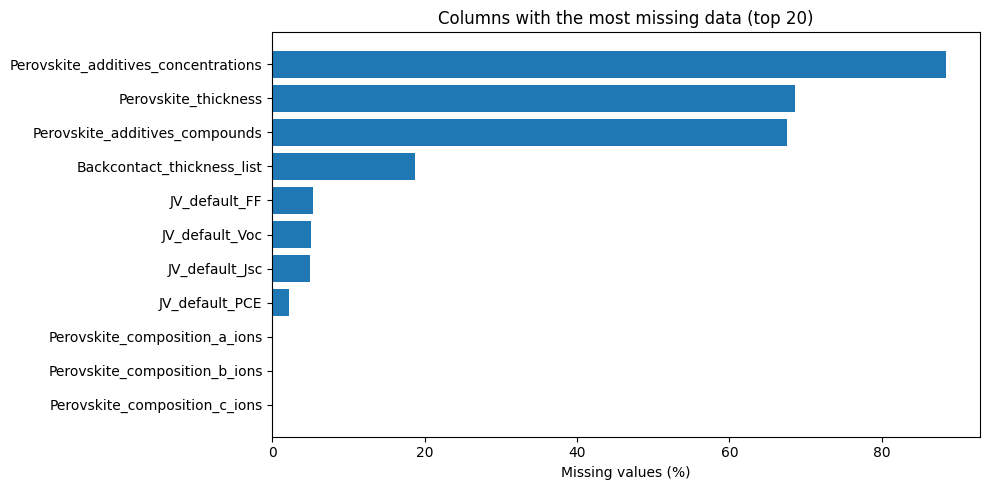

,Target check,Count
0,Total rows,42443
1,Missing/non-numeric PCE,924
2,PCE ≤ 0,72
3,Valid positive PCE,41447


In [7]:
# CELL 4 — Data quality: missing values and target validity
display(Markdown("## 2. Data quality checks"))
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (100 * df.isna().mean()).sort_values(ascending=False)
missing_table = pd.DataFrame({
    "Missing values": missing,
    "Missing (%)": missing_pct.round(2)
})
display(missing_table.head(25))

plt.figure(figsize=(10, 5))
top_missing = missing_pct[missing_pct > 0].head(20).sort_values()
if len(top_missing):
    plt.barh(top_missing.index.astype(str), top_missing.values)
    plt.xlabel("Missing values (%)")
    plt.title("Columns with the most missing data (top 20)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were found.")

target_numeric = pd.to_numeric(df[TARGET], errors="coerce")
display(pd.DataFrame({
    "Target check": ["Total rows", "Missing/non-numeric PCE", "PCE ≤ 0", "Valid positive PCE"],
    "Count": [len(df), int(target_numeric.isna().sum()),
              int((target_numeric <= 0).sum()), int((target_numeric > 0).sum())]
}))


## 3. Exploratory data analysis (EDA)

PCE summary statistics (all numeric target values):


,PCE
count,41519.000000
mean,12.032089
std,5.229161
min,0.000000
25%,8.470000
50%,12.730000
75%,16.100000
max,36.200000


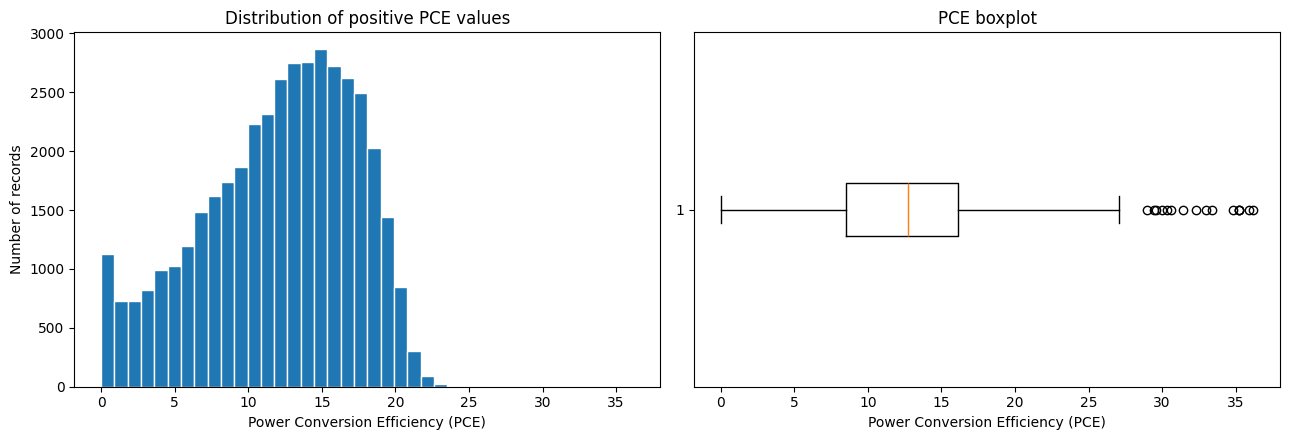

In [8]:
# CELL 5 — Exploratory data analysis: target distribution
display(Markdown("## 3. Exploratory data analysis (EDA)"))
pce_all = pd.to_numeric(df[TARGET], errors="coerce").dropna()
pce_positive = pce_all[pce_all > 0]

print("PCE summary statistics (all numeric target values):")
display(pce_all.describe().to_frame("PCE"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(pce_positive, bins=40, edgecolor="white")
axes[0].set_title("Distribution of positive PCE values")
axes[0].set_xlabel("Power Conversion Efficiency (PCE)")
axes[0].set_ylabel("Number of records")
axes[1].boxplot(pce_positive, vert=False)
axes[1].set_title("PCE boxplot")
axes[1].set_xlabel("Power Conversion Efficiency (PCE)")
plt.tight_layout()
plt.show()


In [9]:
# CELL 6 — Clean data and prepare model inputs
# Use numeric, positive target values. If the measured flag exists, keep records marked measured.
df_model = df.copy()
df_model[TARGET] = pd.to_numeric(df_model[TARGET], errors="coerce")
df_model = df_model.dropna(subset=[TARGET])

if "JV_measured" in df_model.columns:
    measured_text = df_model["JV_measured"].astype(str).str.strip().str.lower()
    df_model = df_model[measured_text.isin(["true", "1", "yes"])].copy()

df_model = df_model[df_model[TARGET] > 0].copy()

# Prevent target leakage by excluding other measured JV outputs and the measured flag.
leakage_cols = [TARGET, "JV_default_Voc", "JV_default_Jsc", "JV_default_FF", "JV_measured"]
X = df_model.drop(columns=[c for c in leakage_cols if c in df_model.columns]).copy()
y = df_model[TARGET].astype(float)

# Convert object columns to numeric when at least 85% of nonmissing entries parse as numbers.
for col in X.select_dtypes(include=["object"]).columns:
    converted = pd.to_numeric(X[col], errors="coerce")
    nonmissing_count = X[col].notna().sum()
    if nonmissing_count > 0 and converted.notna().sum() / nonmissing_count >= 0.85:
        X[col] = converted

# Remove entirely empty columns and obvious ID columns.
X = X.drop(columns=[c for c in X.columns if X[c].isna().all()])
id_like = [c for c in X.columns if c.lower() in {"id", "record_id", "sample_id", "unnamed: 0"}]
X = X.drop(columns=id_like)

if len(X) < 20:
    raise ValueError("Fewer than 20 usable rows remain after cleaning; check the target column and data.")

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print(f"Rows in original dataset: {len(df):,}")
print(f"Rows retained for modelling: {len(df_model):,}")
print(f"Rows excluded during cleaning: {len(df) - len(df_model):,}")
print(f"Input features: {X.shape[1]}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
display(pd.DataFrame({
    "Feature type": ["Numeric", "Categorical", "Total"],
    "Number of columns": [len(numeric_features), len(categorical_features), X.shape[1]]
}))


Rows in original dataset: 42,443
Rows retained for modelling: 41,403
Rows excluded during cleaning: 1,040
Input features: 25
Numeric features: 5
Categorical features: 20


,Feature type,Number of columns
0,Numeric,5
1,Categorical,20
2,Total,25


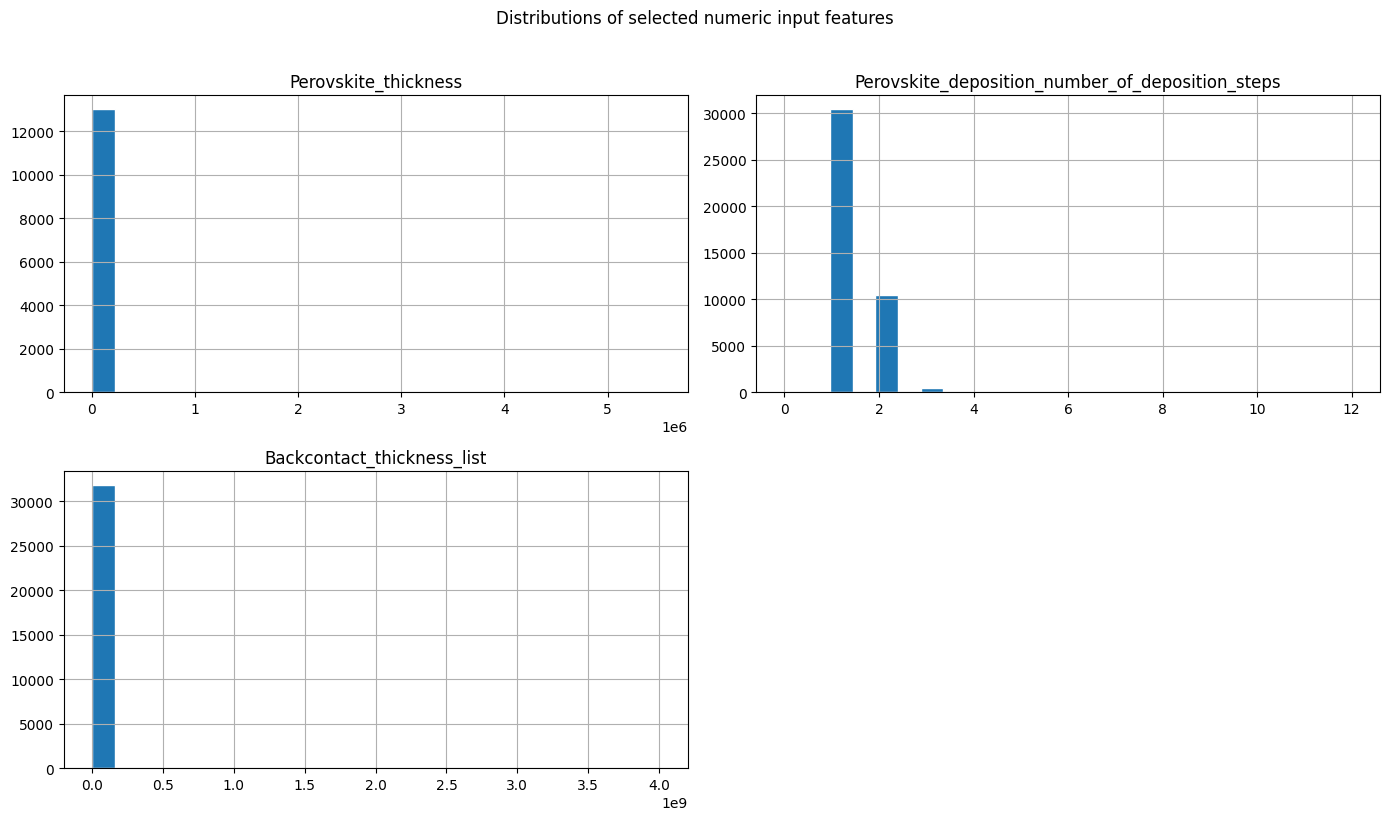

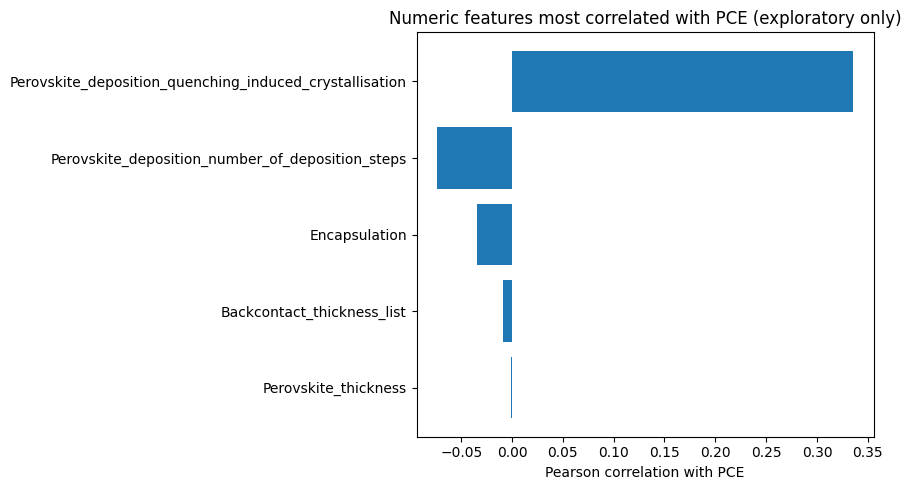

,Correlation with PCE
Perovskite_deposition_quenching_induced_crystallisation,0.335314
Perovskite_deposition_number_of_deposition_steps,-0.073358
Encapsulation,-0.034878
Backcontact_thickness_list,-0.008653
Perovskite_thickness,-0.001054


In [10]:
# CELL 7 — More EDA: numeric feature distributions and target correlations
# Plot a sample of numeric input features to keep the charts readable.
numeric_for_plot = [c for c in numeric_features if X[c].notna().sum() > 0][:8]
if numeric_for_plot:
    X[numeric_for_plot].hist(figsize=(14, 8), bins=25, edgecolor="white")
    plt.suptitle("Distributions of selected numeric input features", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric input features available for histogram plotting.")

numeric_corr_data = X[numeric_features].copy() if numeric_features else pd.DataFrame()
if len(numeric_corr_data.columns):
    numeric_corr_data[TARGET] = y.values
    corr = numeric_corr_data.corr(numeric_only=True)[TARGET].drop(TARGET).dropna()
    corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
    if len(corr):
        plt.figure(figsize=(9, 5))
        plt.barh(corr.index[::-1].astype(str), corr.values[::-1])
        plt.xlabel("Pearson correlation with PCE")
        plt.title("Numeric features most correlated with PCE (exploratory only)")
        plt.tight_layout()
        plt.show()
        display(corr.to_frame("Correlation with PCE"))
    else:
        print("Not enough numeric feature data to calculate correlations.")
else:
    print("No numeric input features available for correlation analysis.")


In [11]:
# CELL 8 — Preprocessing and train/test split
# Numeric columns: median imputation.
# Categorical columns: most-frequent imputation and one-hot encoding.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=15))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
], remainder="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

display(pd.DataFrame({
    "Dataset split": ["Training", "Testing", "Total"],
    "Rows": [len(X_train), len(X_test), len(X_train) + len(X_test)],
    "Percentage": [80, 20, 100]
}))


,Dataset split,Rows,Percentage
0,Training,33122,80
1,Testing,8281,20
2,Total,41403,100


In [12]:
# CELL 9 — Train the XGBoost regression model
xgb = XGBRegressor(
    n_estimators=350,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=2.0,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    n_jobs=4,
    random_state=RANDOM_STATE
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", xgb)
])

print("Training XGBoost model. Please wait...")
model.fit(X_train, y_train)
print("Training complete.")


Training XGBoost model. Please wait...
Training complete.


In [13]:

# Save the COMPLETE fitted preprocessing + XGBoost pipeline

import joblib
import os
from google.colab import files

# Confirm that the model has been trained
print("Model type:", type(model).__name__)

# Save the full fitted pipeline
joblib.dump(model, "solar_cell_model.joblib")

# Test that the saved file can be loaded
loaded_model = joblib.load("solar_cell_model.joblib")

# Verify predictions using the same test features used in training
test_predictions = loaded_model.predict(X_test.head(5))

print("Saved model loaded successfully!")
print("Sample predictions:", test_predictions)

# Download the file to your computer
files.download("solar_cell_model.joblib")


Model type: Pipeline
Saved model loaded successfully!
Sample predictions: [12.144925 11.281793 14.410425 11.899769 15.656051]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# CELL 10 — Model evaluation: MAE, RMSE and R²
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Value": [mae, rmse, r2],
    "Meaning": [
        "Average absolute prediction error (PCE points); lower is better",
        "Penalizes larger errors more strongly (PCE points); lower is better",
        "Variance explained by the model; closer to 1 is generally better"
    ]
})
display(Markdown("## 4. Model evaluation"))
display(metrics.style.format({"Value": "{:.4f}"}))


## 4. Model evaluation

,Metric,Value,Meaning
0,MAE,2.7223,Average absolute prediction error (PCE points); lower is better
1,RMSE,3.5491,Penalizes larger errors more strongly (PCE points); lower is better
2,R²,0.5335,Variance explained by the model; closer to 1 is generally better


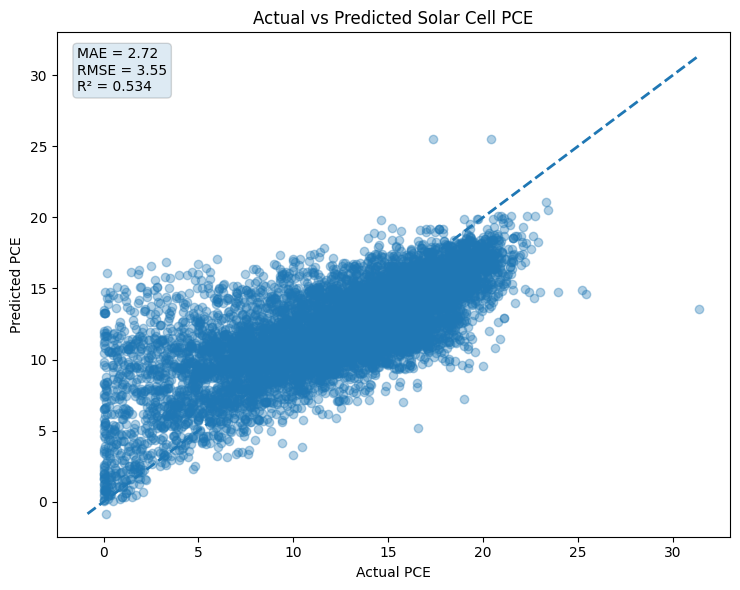

How to read this graph: points close to the dashed line are more accurate predictions.


In [15]:
# CELL 11 — Clear graph: actual PCE versus predicted PCE
actual = np.asarray(y_test)
pred = np.asarray(predictions)
low = min(float(np.min(actual)), float(np.min(pred)))
high = max(float(np.max(actual)), float(np.max(pred)))

plt.figure(figsize=(7.5, 6))
plt.scatter(actual, pred, alpha=0.35)
plt.plot([low, high], [low, high], linestyle="--", linewidth=2)
plt.xlabel("Actual PCE")
plt.ylabel("Predicted PCE")
plt.title("Actual vs Predicted Solar Cell PCE")
plt.text(0.03, 0.97, f"MAE = {mae:.2f}\nRMSE = {rmse:.2f}\nR² = {r2:.3f}",
         transform=plt.gca().transAxes, va="top",
         bbox=dict(boxstyle="round", alpha=0.15))
plt.tight_layout()
plt.show()

print("How to read this graph: points close to the dashed line are more accurate predictions.")


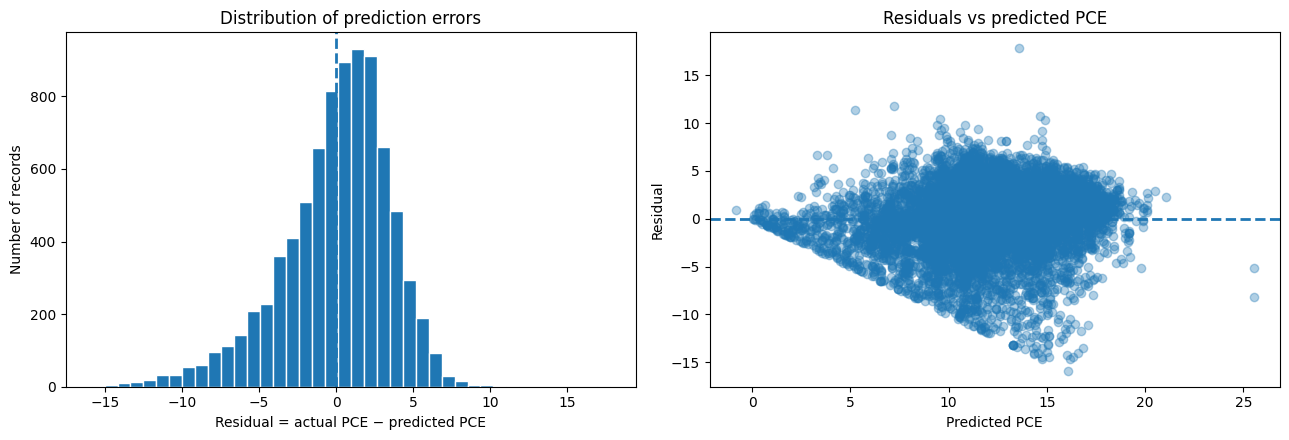

Residuals near zero indicate accurate predictions. Patterns or wide spread may indicate systematic errors.


In [16]:
# CELL 12 — Error analysis: residual distribution and residual vs predicted
residuals = actual - pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(residuals, bins=40, edgecolor="white")
axes[0].axvline(0, linestyle="--", linewidth=2)
axes[0].set_title("Distribution of prediction errors")
axes[0].set_xlabel("Residual = actual PCE − predicted PCE")
axes[0].set_ylabel("Number of records")

axes[1].scatter(pred, residuals, alpha=0.35)
axes[1].axhline(0, linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs predicted PCE")
axes[1].set_xlabel("Predicted PCE")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

print("Residuals near zero indicate accurate predictions. Patterns or wide spread may indicate systematic errors.")


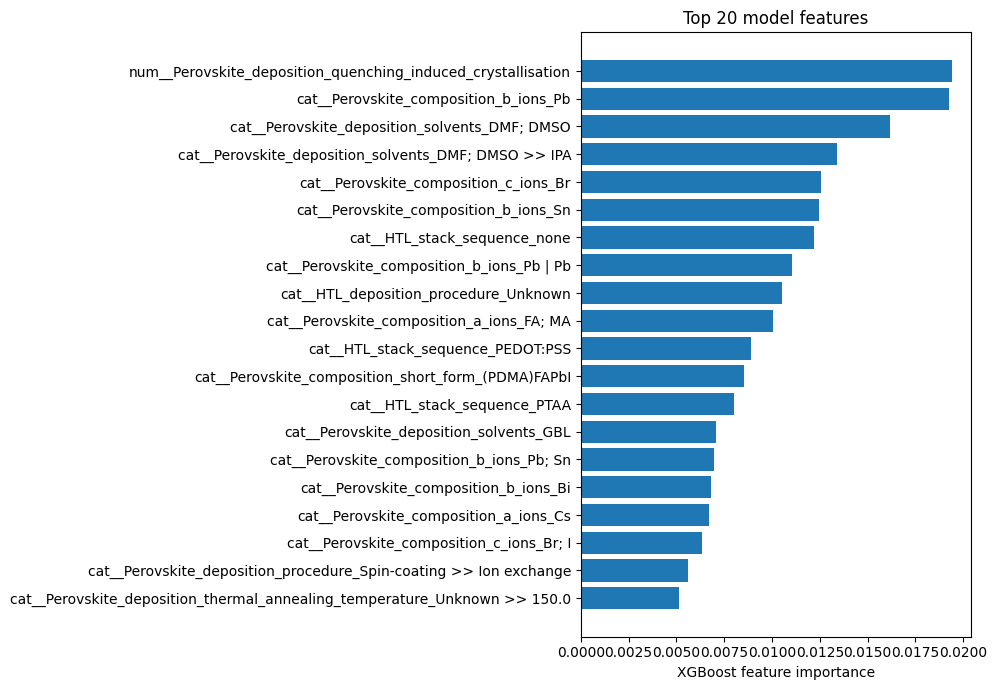

,Feature,Importance
0,num__Perovskite_deposition_quenching_induced_c...,0.019413
1,cat__Perovskite_composition_b_ions_Pb,0.019267
2,cat__Perovskite_deposition_solvents_DMF; DMSO,0.016170
3,cat__Perovskite_deposition_solvents_DMF; DMSO ...,0.013418
4,cat__Perovskite_composition_c_ions_Br,0.012538
5,cat__Perovskite_composition_b_ions_Sn,0.012458
6,cat__HTL_stack_sequence_none,0.012189
7,cat__Perovskite_composition_b_ions_Pb | Pb,0.011049
8,cat__HTL_deposition_procedure_Unknown,0.010531
9,cat__Perovskite_composition_a_ions_FA; MA,0.010073


Feature importance describes how the fitted model uses inputs; it does not prove causation.


In [17]:
# CELL 13 — Feature importance graph
# XGBoost importance is calculated after preprocessing. One-hot encoded category values may appear separately.
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_xgb = model.named_steps["regressor"]
try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_xgb.feature_importances_
    imp = pd.DataFrame({"Feature": transformed_names, "Importance": importances})
    imp = imp.sort_values("Importance", ascending=False).head(20).sort_values("Importance")
    plt.figure(figsize=(10, 7))
    plt.barh(imp["Feature"].astype(str), imp["Importance"])
    plt.xlabel("XGBoost feature importance")
    plt.title("Top 20 model features")
    plt.tight_layout()
    plt.show()
    display(imp.sort_values("Importance", ascending=False).reset_index(drop=True))
except Exception as e:
    print("Feature importance plot could not be generated:", e)

print("Feature importance describes how the fitted model uses inputs; it does not prove causation.")


## 5. Candidate recipe ranking demo

Top 15 records with the highest predicted PCE in the test split:

,Predicted_Rank,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,...,Perovskite_deposition_thermal_annealing_time,HTL_stack_sequence,HTL_deposition_procedure,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,Actual_PCE,Predicted_PCE
0,1,SLG | ITO | ZnO-np | SnO2-np | Perovskite | Sp...,nip,SLG | ITO,ZnO-np | SnO2-np,Spin-coating | Spin-coating,MA,Pb,I,MAPbI,...,3.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,20.43,25.545000
1,2,SLG | ITO | ZnO-np | SnO2-np | Perovskite | Sp...,nip,SLG | ITO,ZnO-np | SnO2-np,Spin-coating | Spin-coating,MA,Pb,I,MAPbI,...,3.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,17.34,25.545000
2,3,SLG | ITO | SnO2-c | Perovskite | PEAI | Spiro...,nip,SLG | ITO,SnO2-c,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,PEAI | Spiro-MeOTAD,Spin-coating | Spin-coating,Au,80.0,Evaporation,False,Unknown,23.32,21.059000
3,4,SLG | ITO | SnO2-np | Perovskite | PEAI | Spir...,nip,SLG | ITO,SnO2-np,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,PEAI | Spiro-MeOTAD,Spin-coating | Spin-coating,Au,80.0,Evaporation,False,Unknown,23.40,20.493999
4,5,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,FA; MA | (C6H13NH3),Pb | Pb,Br; I | I,FAMAPbBrI | (C6H13NH3)PbI,...,10.0 >> Unknown,C6Br | Spiro-MeOTAD,Spin-coating | Spin-coating,Au,100.0,Evaporation,False,Unknown,22.30,20.124001
5,6,SLG | ITO | SnO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | ITO,SnO2-c,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,20.78,20.089001
6,7,SLG | ITO | SnO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | ITO,SnO2-c,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,22.73,20.089001
7,8,SLG | ITO | SnO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | ITO,SnO2-c,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,21.48,20.089001
8,9,SLG | ITO | SnO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | ITO,SnO2-c,Spin-coating,FA; MA,Pb,I,FAMAPbI,...,1.0 >> 15.0,Spiro-MeOTAD,Spin-coating,Au,80.0,Evaporation,False,Unknown,20.95,20.089001
9,10,SLG | ITO | PTAA | Perovskite | PCBM-60 | C60 ...,pin,SLG | ITO,PCBM-60 | C60 | BCP,Spin-coating | Evaporation | Evaporation,FA; MA,Pb,Br; I,FAMAPbBrI,...,10.0; 10.0,PTAA,Spin-coating,Cu,80.0,Evaporation,False,Unknown,21.10,19.931000


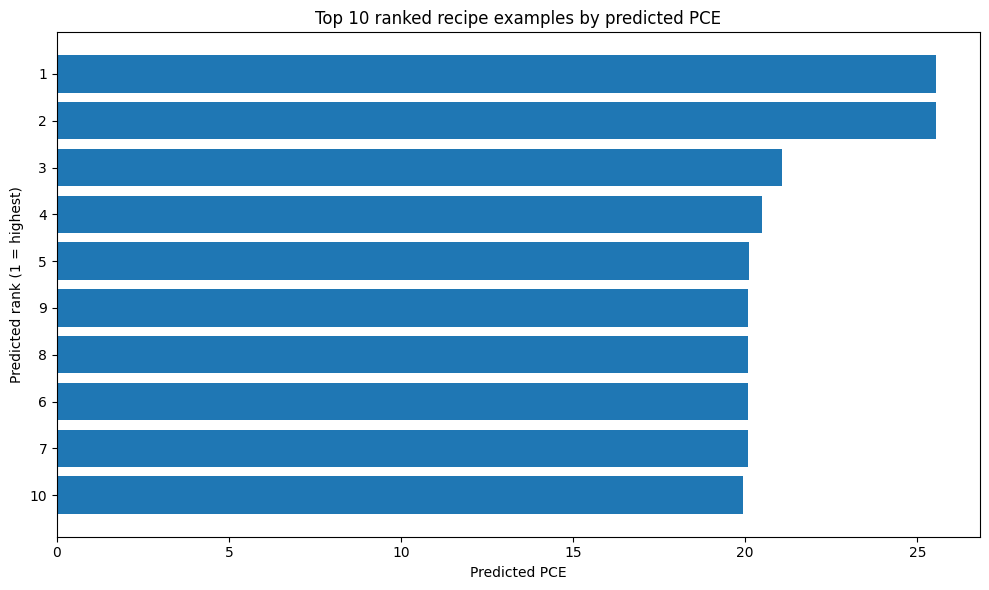

In [18]:
# CELL 14 — Optimization demo: rank test-set recipes by predicted PCE
# This ranks existing held-out records as a demonstration; they are not newly invented candidates.
ranking = X_test.copy().reset_index(drop=True)
ranking["Actual_PCE"] = np.asarray(y_test)
ranking["Predicted_PCE"] = predictions
ranking = ranking.sort_values("Predicted_PCE", ascending=False).reset_index(drop=True)
ranking.insert(0, "Predicted_Rank", np.arange(1, len(ranking) + 1))

display(Markdown("## 5. Candidate recipe ranking demo"))
display(Markdown("Top 15 records with the highest predicted PCE in the test split:"))
display(ranking.head(15).round(3))

top_n = ranking.head(10).copy().sort_values("Predicted_PCE")
plt.figure(figsize=(10, 6))
plt.barh(top_n["Predicted_Rank"].astype(str), top_n["Predicted_PCE"])
plt.xlabel("Predicted PCE")
plt.ylabel("Predicted rank (1 = highest)")
plt.title("Top 10 ranked recipe examples by predicted PCE")
plt.tight_layout()
plt.show()


In [19]:
# CELL 15 — Example prediction for one input recipe
# This selects one held-out example and predicts its PCE, showing the inference step.
example_recipe = X_test.iloc[[0]].copy()
example_prediction = float(model.predict(example_recipe)[0])
example_actual = float(y_test.iloc[0])

display(Markdown("## 6. Example AI prediction"))
print(f"Predicted PCE: {example_prediction:.3f}")
print(f"Actual PCE in dataset: {example_actual:.3f}")
print(f"Absolute error for this example: {abs(example_actual - example_prediction):.3f} PCE points")
display(Markdown("Input recipe features (first 20 columns shown):"))
display(example_recipe.iloc[:, :20])


## 6. Example AI prediction

Predicted PCE: 12.145
Actual PCE in dataset: 12.300
Absolute error for this example: 0.155 PCE points


Input recipe features (first 20 columns shown):

,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,Perovskite_additives_concentrations,Perovskite_thickness,Perovskite_deposition_number_of_deposition_steps,Perovskite_deposition_procedure,Perovskite_deposition_solvents,Perovskite_deposition_quenching_induced_crystallisation,Perovskite_deposition_thermal_annealing_temperature,Perovskite_deposition_thermal_annealing_time,HTL_stack_sequence,HTL_deposition_procedure
34495,SLG | ITO | PEDOT:PSS | Perovskite | NDI-BTH2 ...,pin,SLG | ITO,NDI-BTH2,Spin-coating,FA; MA,Pb,I,FAMAPbI,Cl,NaN,NaN,1,Spin-coating,DMSO; GBL,True,100.0,20.0,PEDOT:PSS,Spin-coating


In [20]:
# CELL 16 — Final project report
display(Markdown("## 7. Final project summary"))
summary = pd.DataFrame({
    "Project item": [
        "Problem type", "Algorithm", "Prediction target", "Rows used",
        "Input features", "Training rows", "Testing rows", "MAE", "RMSE", "R²"
    ],
    "Result": [
        "Supervised regression", "XGBoost Regressor", TARGET, f"{len(df_model):,}",
        str(X.shape[1]), f"{len(X_train):,}", f"{len(X_test):,}",
        f"{mae:.4f}", f"{rmse:.4f}", f"{r2:.4f}"
    ]
})
display(summary)

print("\nConclusion:")
print(f"The trained XGBoost model predicts {TARGET} from the available material/device/process features.")
print(f"On the held-out test split, MAE={mae:.3f}, RMSE={rmse:.3f}, and R²={r2:.3f}.")
print("Use the graphs and metrics above to discuss model performance.")
print("Important limitation: predictions and rankings are estimates, not experimental confirmation.")


## 7. Final project summary

,Project item,Result
0,Problem type,Supervised regression
1,Algorithm,XGBoost Regressor
2,Prediction target,JV_default_PCE
3,Rows used,"41,403"
4,Input features,25
5,Training rows,"33,122"
6,Testing rows,"8,281"
7,MAE,2.7223
8,RMSE,3.5491
9,R²,0.5335



Conclusion:
The trained XGBoost model predicts JV_default_PCE from the available material/device/process features.
On the held-out test split, MAE=2.722, RMSE=3.549, and R²=0.534.
Use the graphs and metrics above to discuss model performance.
Important limitation: predictions and rankings are estimates, not experimental confirmation.
